# Klasifikasi Kondisi Tanah – Alat Penyiram Tanaman Otomatis
Model: **Decision Tree**, **Random Forest**, **SVM (RBF)**  
Kelas: Kering · Optimal · Terlalu Basah  
Fitur: Suhu (°C), Kelembapan udara (%RH), ADC tanah

## 1. Setup library

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib, os
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
sns.set_theme(style='whitegrid')
os.makedirs('hasil', exist_ok=True)   # semua gambar & tabel disimpan di folder 'hasil' untuk PPT
RANDOM_STATE = 42

## 2. Upload & baca dataset
Upload file `Dataset_Smart_Irrigation_300_Data_Terpilih_1.xlsx` saat diminta.

In [2]:
try:
    from google.colab import files
    up = files.upload()
    PATH = list(up.keys())[0]
except ImportError:
    PATH = 'Dataset_Smart_Irrigation_300_Data_Terpilih_1.xlsx'   # kalau dijalankan di luar Colab

# Sheet Kering / Optimal / Terlalu Basah sudah berlabel di kolom 'Kondisi tanah'
df = pd.concat([pd.read_excel(PATH, sheet_name=s) for s in ['Kering','Optimal','Terlalu Basah']],
               ignore_index=True)
df = df.rename(columns={'Suhu (°C)':'Suhu','Kelembapan udara (%RH)':'RH','ADC tanah':'ADC',
                        'Kondisi tanah':'Kondisi'})
df = df[['Suhu','RH','ADC','Kondisi']]     # kolom waktu & nomor baris dibuang (bukan fitur sensor, rawan kebocoran data)
print(df.shape); print(df.isnull().sum()); df.head()

Saving Dataset_Smart_Irrigation_300_Data_Terpilih (1).xlsx to Dataset_Smart_Irrigation_300_Data_Terpilih (1).xlsx
(300, 4)
Suhu       0
RH         0
ADC        0
Kondisi    0
dtype: int64


,Suhu,RH,ADC,Kondisi
0,35.2,29,2973,Kering
1,35.2,29,2979,Kering
2,35.2,29,3013,Kering
3,35.2,29,3006,Kering
4,35.2,29,3002,Kering


## 3. Eksplorasi data

Kondisi
Kering           100
Optimal          100
Terlalu Basah    100
Name: count, dtype: int64


Suhu              RH             ADC              
                min   max  mean min max  mean   min   max    mean
Kondisi                                                          
Kering         35.2  43.0  36.3  12  29  26.2  2934  3017  2994.9
Optimal        30.8  33.8  32.8  41  50  44.3  1518  1549  1532.1
Terlalu Basah  30.2  41.6  34.8  20  98  55.2  1033  1193  1056.3

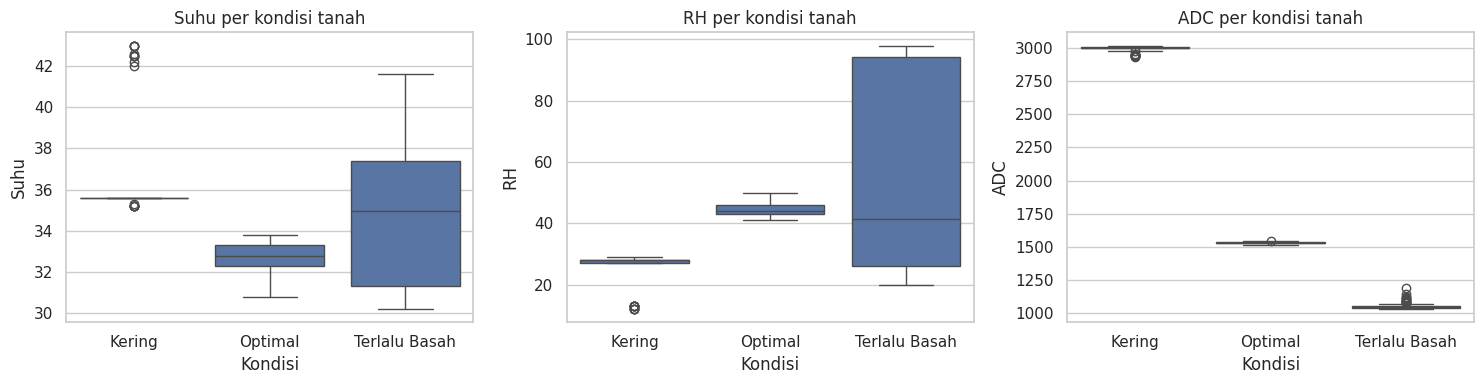

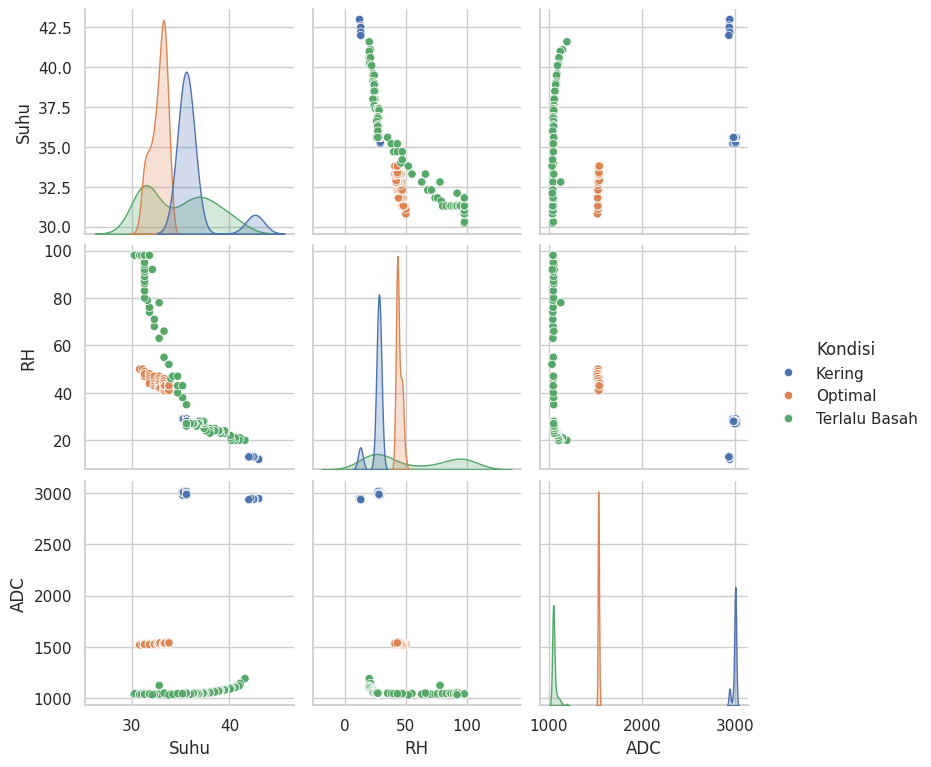

In [3]:
print(df['Kondisi'].value_counts())
display(df.groupby('Kondisi').agg(['min','max','mean']).round(1))

fig, ax = plt.subplots(1,3, figsize=(15,4))
order = ['Kering','Optimal','Terlalu Basah']
for a,c in zip(ax, ['Suhu','RH','ADC']):
    sns.boxplot(data=df, x='Kondisi', y=c, order=order, ax=a); a.set_title(f'{c} per kondisi tanah')
plt.tight_layout(); plt.savefig('hasil/eda_boxplot.png', dpi=200); plt.show()

sns.pairplot(df, hue='Kondisi', hue_order=order, height=2.6)
plt.savefig('hasil/eda_pairplot.png', dpi=200); plt.show()

## 4. Fungsi training & evaluasi
Dua skenario dijalankan:
- **Skenario A** – 3 fitur (Suhu, RH, ADC): kondisi sebenarnya di alat.
- **Skenario B** – tanpa ADC (Suhu & RH saja): uji lebih berat, untuk melihat perbedaan kemampuan antar model.

Pembagian data 80% latih / 20% uji (stratified), ditambah 5-fold cross validation agar hasil lebih dapat dipercaya.

In [4]:
LABELS = ['Kering','Optimal','Terlalu Basah']

def get_models():
    return {
        'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
        'SVM (RBF)':     Pipeline([('scale', StandardScaler()),
                                   ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_STATE))]),
    }

def run_scenario(features, tag):
    X, y = df[features], df['Kondisi']
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows, trained = [], {}
    fig, axes = plt.subplots(1,3, figsize=(15,4))
    for ax,(name,model) in zip(axes, get_models().items()):
        model.fit(X_tr, y_tr); pred = model.predict(X_te); trained[name]=model
        cvs = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
        rows.append({'Model':name,
                     'Akurasi Train (%)': accuracy_score(y_tr, model.predict(X_tr))*100,
                     'Akurasi Test (%)':  accuracy_score(y_te, pred)*100,
                     'Precision (%)': precision_score(y_te, pred, average='macro', zero_division=0)*100,
                     'Recall (%)':    recall_score(y_te, pred, average='macro', zero_division=0)*100,
                     'F1-score (%)':  f1_score(y_te, pred, average='macro', zero_division=0)*100,
                     'CV 5-fold Mean (%)': cvs.mean()*100, 'CV Std (%)': cvs.std()*100})
        print(f'===== {name} [{tag}] ====='); print(classification_report(y_te, pred, labels=LABELS, zero_division=0))
        ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=LABELS), display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(name); ax.tick_params(axis='x', rotation=20)
    plt.suptitle(f'Confusion Matrix – {tag}'); plt.tight_layout()
    plt.savefig(f'hasil/confusion_{tag[:10].replace(" ","_")}.png', dpi=200); plt.show()
    res = pd.DataFrame(rows).set_index('Model').round(2)
    res.to_csv(f'hasil/perbandingan_{tag[:10].replace(" ","_")}.csv')
    return res, trained, (X_tr, X_te, y_tr, y_te)

## 5. Skenario A – Suhu + RH + ADC

===== Decision Tree [Skenario A (3 fitur)] =====
               precision    recall  f1-score   support

       Kering       1.00      1.00      1.00        20
      Optimal       1.00      1.00      1.00        20
Terlalu Basah       1.00      1.00      1.00        20

     accuracy                           1.00        60
    macro avg       1.00      1.00      1.00        60
 weighted avg       1.00      1.00      1.00        60

===== Random Forest [Skenario A (3 fitur)] =====
               precision    recall  f1-score   support

       Kering       1.00      1.00      1.00        20
      Optimal       1.00      1.00      1.00        20
Terlalu Basah       1.00      1.00      1.00        20

     accuracy                           1.00        60
    macro avg       1.00      1.00      1.00        60
 weighted avg       1.00      1.00      1.00        60

===== SVM (RBF) [Skenario A (3 fitur)] =====
               precision    recall  f1-score   support

       Kering       1.00 

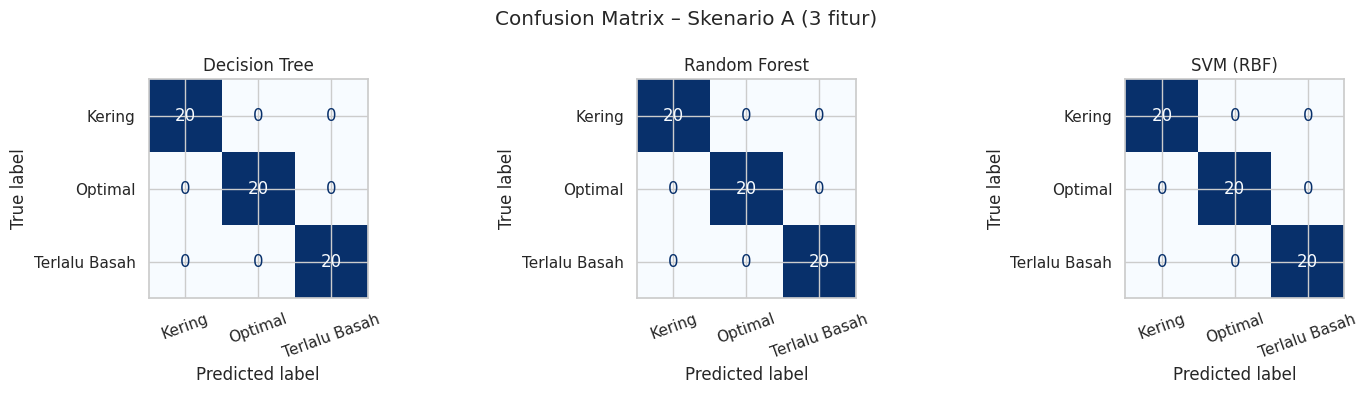

,Akurasi Train (%),Akurasi Test (%),Precision (%),Recall (%),F1-score (%),CV 5-fold Mean (%),CV Std (%)
Model,,,,,,,
Decision Tree,100.0,100.0,100.0,100.0,100.0,100.0,0.0
Random Forest,100.0,100.0,100.0,100.0,100.0,100.0,0.0
SVM (RBF),100.0,100.0,100.0,100.0,100.0,100.0,0.0


In [5]:
resA, modelsA, splitA = run_scenario(['Suhu','RH','ADC'], 'Skenario A (3 fitur)')
display(resA)

## 6. Skenario B – Suhu + RH saja (tanpa ADC)

===== Decision Tree [Skenario B (tanpa ADC)] =====
               precision    recall  f1-score   support

       Kering       0.95      1.00      0.98        20
      Optimal       0.91      1.00      0.95        20
Terlalu Basah       1.00      0.85      0.92        20

     accuracy                           0.95        60
    macro avg       0.95      0.95      0.95        60
 weighted avg       0.95      0.95      0.95        60

===== Random Forest [Skenario B (tanpa ADC)] =====
               precision    recall  f1-score   support

       Kering       0.95      1.00      0.98        20
      Optimal       0.91      1.00      0.95        20
Terlalu Basah       1.00      0.85      0.92        20

     accuracy                           0.95        60
    macro avg       0.95      0.95      0.95        60
 weighted avg       0.95      0.95      0.95        60

===== SVM (RBF) [Skenario B (tanpa ADC)] =====
               precision    recall  f1-score   support

       Kering      

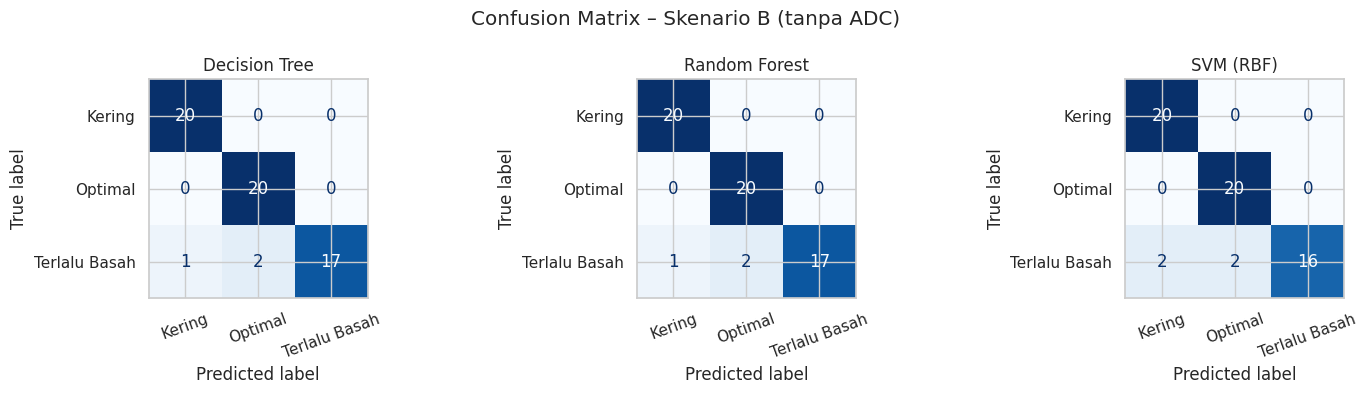

,Akurasi Train (%),Akurasi Test (%),Precision (%),Recall (%),F1-score (%),CV 5-fold Mean (%),CV Std (%)
Model,,,,,,,
Decision Tree,97.92,95.00,95.38,95.00,94.90,98.00,2.45
Random Forest,99.17,95.00,95.38,95.00,94.90,98.33,2.11
SVM (RBF),93.33,93.33,93.94,93.33,93.12,93.33,2.98


In [6]:
resB, modelsB, splitB = run_scenario(['Suhu','RH'], 'Skenario B (tanpa ADC)')
display(resB)

## 7. Perbandingan model

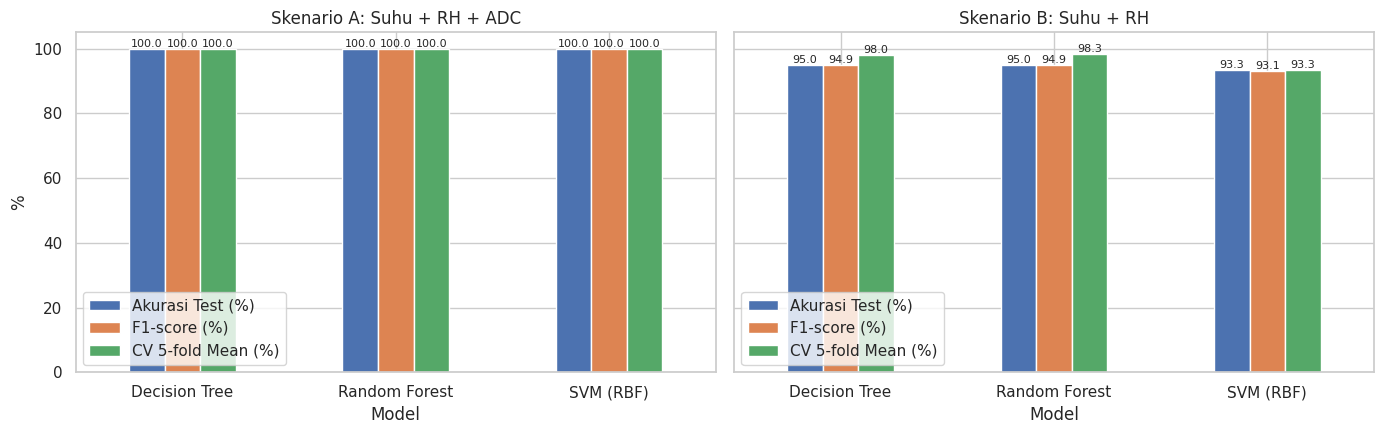

Model terbaik Skenario A (CV): Decision Tree → 100.0 %
Model terbaik Skenario B (CV): Random Forest → 98.33 %


In [7]:
fig, ax = plt.subplots(1,2, figsize=(14,4.5), sharey=True)
for a,(res,t) in zip(ax, [(resA,'Skenario A: Suhu + RH + ADC'),(resB,'Skenario B: Suhu + RH')]):
    res[['Akurasi Test (%)','F1-score (%)','CV 5-fold Mean (%)']].plot.bar(ax=a, rot=0)
    a.set_title(t); a.set_ylabel('%'); a.set_ylim(0,105)
    for c in a.containers: a.bar_label(c, fmt='%.1f', fontsize=8)
plt.tight_layout(); plt.savefig('hasil/perbandingan_model.png', dpi=200); plt.show()

best = resA['CV 5-fold Mean (%)'].idxmax()
print('Model terbaik Skenario A (CV):', best, '→', resA.loc[best,'CV 5-fold Mean (%)'], '%')
best = resB['CV 5-fold Mean (%)'].idxmax()
print('Model terbaik Skenario B (CV):', best, '→', resB.loc[best,'CV 5-fold Mean (%)'], '%')

## 8. Visualisasi Decision Tree & Feature Importance

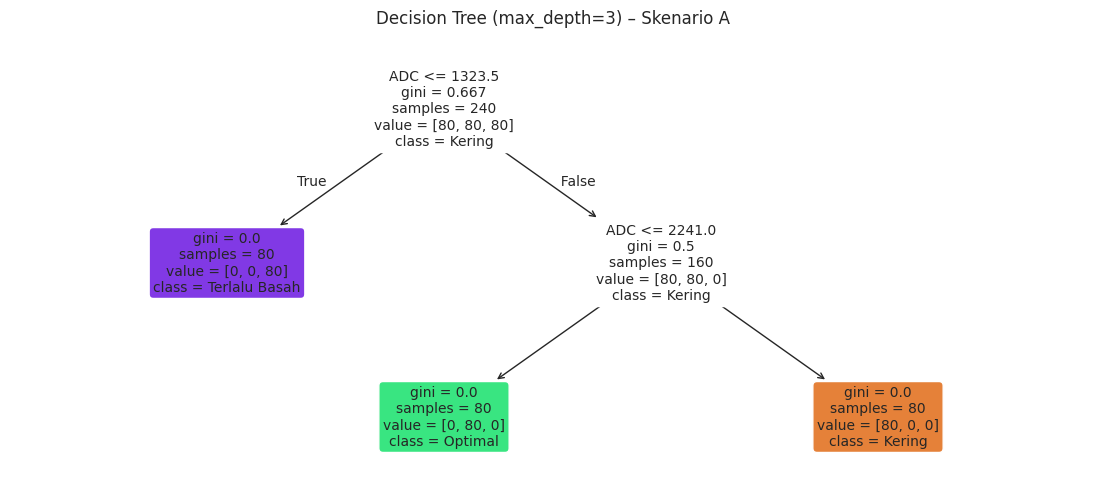

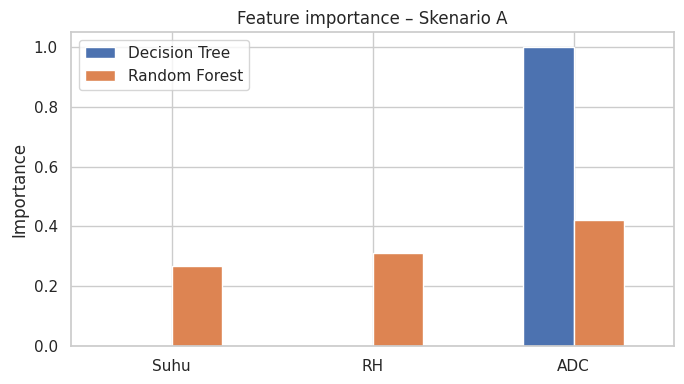

,Decision Tree,Random Forest
Suhu,0.0,0.266
RH,0.0,0.311
ADC,1.0,0.423


In [8]:
X_tr = splitA[0]
plt.figure(figsize=(14,6))
plot_tree(modelsA['Decision Tree'], feature_names=['Suhu','RH','ADC'], class_names=modelsA['Decision Tree'].classes_,
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (max_depth=3) – Skenario A'); plt.savefig('hasil/decision_tree.png', dpi=200, bbox_inches='tight'); plt.show()

imp = pd.DataFrame({'Decision Tree': modelsA['Decision Tree'].feature_importances_,
                    'Random Forest': modelsA['Random Forest'].feature_importances_}, index=['Suhu','RH','ADC'])
imp.plot.bar(rot=0, figsize=(7,4)); plt.title('Feature importance – Skenario A'); plt.ylabel('Importance')
plt.tight_layout(); plt.savefig('hasil/feature_importance.png', dpi=200); plt.show()
display(imp.round(3))

## 9. Simpan model & contoh inferensi (data sensor baru)

In [9]:
best_name = resA['CV 5-fold Mean (%)'].idxmax()
joblib.dump(modelsA[best_name], 'hasil/model_terbaik.pkl')

# contoh: Suhu, RH, ADC dari sensor
baru = pd.DataFrame([[35.5, 28, 3000], [32.8, 44, 1530], [31.0, 80, 1050]], columns=['Suhu','RH','ADC'])
for name, m in modelsA.items():
    baru[name] = m.predict(baru[['Suhu','RH','ADC']])
display(baru)

# Aksi alat: siram hanya kalau tanah Kering
baru['Pompa'] = np.where(baru[best_name]=='Kering', 'ON (siram)', 'OFF')
display(baru[['Suhu','RH','ADC',best_name,'Pompa']])

,Suhu,RH,ADC,Decision Tree,Random Forest,SVM (RBF)
0,35.5,28,3000,Kering,Kering,Kering
1,32.8,44,1530,Optimal,Optimal,Optimal
2,31.0,80,1050,Terlalu Basah,Terlalu Basah,Terlalu Basah


,Suhu,RH,ADC,Decision Tree,Pompa
0,35.5,28,3000,Kering,ON (siram)
1,32.8,44,1530,Optimal,OFF
2,31.0,80,1050,Terlalu Basah,OFF


## 10. Unduh semua hasil untuk PPT
Folder `hasil/` berisi gambar (EDA, confusion matrix, perbandingan, pohon keputusan) dan tabel CSV.

In [10]:
try:
    import shutil; shutil.make_archive('hasil','zip','hasil')
    from google.colab import files; files.download('hasil.zip')
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>